# Heart Signal Reconstruction & MISO RLS Hyperparameter Optimization Pipeline (Project 2)

This notebook implements the **Project 2** end-to-end pipeline for **reconstructing the cardiac signal** and **estimating Heart Rate (BPM)** from individual 5-dimensional wrist-worn PPG and triaxial accelerometer windows (`[ppg1, ppg2, accx, accy, accz]`, $N = 1000$ samples at $f_s = 125\text{ Hz}$, i.e., $8\text{ s}$ per window) using the **Recursive Least Squares (RLS)** adaptive filter and comparing its performance against the optimal **NLMS** and **VS-LMS** algorithms obtained in Project 1.

---

## 1. Pipeline Architecture

To ensure a fair comparison with Project 1 under identical conditions, preprocessing, reference construction, SNR-weighted late fusion, and heart rate detection follow the exact same modular structure:

1. **Minimal Preprocessing (`preprocessing.py`)**:
   - **Zero-Phase Bandpass Filter (`0.5 Hz – 4.0 Hz` $\equiv$ `30 BPM – 240 BPM`)**: 4th-order Butterworth `sosfiltfilt` applied to the 5 channels `[ppg1, ppg2, accx, accy, accz]`.
   - **Amplitude Normalization**: Each channel is normalized to zero mean and unit standard deviation.

2. **Dilated MISO Reference Signal Construction (`reference_construction.py`)**:
   - Because `[0.5, 4.0] Hz` at $f_s = 125\text{ Hz}$ occupies only $5.6\%$ of the Nyquist band (oversampled $\sim 15.6\times$), unit-stride delays ($D=1$) induce severe collinearity ($\chi(\mathbf{R}_a) \gg 10^6$) and a short temporal aperture. We construct a dilated $3M$-tap regressor with tunable stride $D \in \{1, 2, 3, 4\}$:
     $$\mathbf{a}_k^{(D)}[n] = [a_k[n],\; a_k[n-D],\; \dots,\; a_k[n-(M-1)D]]^T, \qquad \hat{m}[n] = \mathbf{w}^T[n]\mathbf{a}[n]$$

3. **Parallel Re-Architected MISO RLS & SNR-Weighted Late Fusion (`LMS_algorithms.py` & `fusion.py`)**:
   - Filters `ppg1` ($d_1[n]$) and `ppg2` ($d_2[n]$) in parallel against $\mathbf{a}[n]$ to obtain the cleared cardiac signals $e_1[n] = d_1[n] - \hat{m}_1[n]$ and $e_2[n] = d_2[n] - \hat{m}_2[n]$.
   - **Re-Architected Recursive Least Squares (`rls`)**:
     - **Dimension-Invariant Initialization**: $\mathbf{P}[0] = (\delta \cdot 3M)^{-1}\mathbf{I}_{3M}$, making $\delta$ invariant to filter order $M$.
     - **Effective Memory Horizon Reparameterization**: $\lambda = 1 - 1 / N_{\text{eff}}$ with $N_{\text{eff}} \in [150, 2500]$ sampled log-uniformly to prevent boundary pinning.
     - **Persistent Diagonal Loading (`diag_load`)**: $\mathbf{P}[n+1] = (1 - \tau)\lambda^{-1}(\mathbf{P}[n] - \mathbf{k}[n]\boldsymbol{\pi}^T[n]) + \tau P_0 \mathbf{I}_{3M}$ with $\tau = (1-\lambda)\cdot\text{diag\_load}$, bounding null-space eigenvalues when $\lambda < 1$.
     - **Huber M-Estimator Robust Innovation Clipping (`huber_c`)**: Bounds impulsive motion/saturation shocks $\tilde{e}[n] = \text{clip}(e[n], \pm c_{\text{huber}}\hat{\sigma}_e[n])$ in the weight update $\mathbf{w}[n+1] = \mathbf{w}[n] + \mathbf{k}[n]\tilde{e}[n]$.
     - **Intra-Window Reverse-Time Warm-Starting (`warm_start_ratio`)**: Pre-runs a reverse-time pass over the first `warm_start_ratio * N` samples of the *current isolated window* ($n = N_{\text{warm}}-1 \to 0$) so $\mathbf{w}[0]$ starts already converged at $n=0$ without any cross-window state propagation.
   - **Project 1 Optimal Benchmarks (`nlms` & `vs_lms`)**:
     - **Normalized LMS (`nlms`)**: Fixed at Project 1 optimal parameters ($M = 22$, $\mu = 0.01288$, $\delta = 0.5$, Periodogram with $\text{NFFT}=4096$, Hann window).
     - **Variable Step-Size LMS (`vs_lms`)**: Fixed at Project 1 optimal parameters ($M = 18$, $\mu_{\max} = 0.06558$, $\mu_{\min} = 0.00791$, $\alpha = 0.98503$, $\gamma = 0.00053$, $\delta = 1.0$, Periodogram with $\text{NFFT}=8192$, Hamming window).
   - **SNR-Weighted Late Fusion**: Combines $e_1[n]$ and $e_2[n]$ using their in-band cardiac spectral SNR weights $w_i = \frac{\text{SNR}_i}{\text{SNR}_1 + \text{SNR}_2}$:
     $$e_{\text{fused}}[n] = w_1 e_1[n] + w_2 e_2[n]$$

4. **Direct Heart Rate Detection (`bpm_detection.py`)**:
   - **Zero-Padded Periodogram (`periodogram`)**: Hann/Hamming/Blackman tapered, zero-padded FFT peak detection in `[0.5, 4.0] Hz`.
   - **Elgendi's Systolic Peak Detection (`elgendi`)**: Two-moving-average systolic peak detector.

5. **Leakage-Free Subject-Wise Group K-Fold Optimization of RLS (`optimization.py`)**:
   - Optimizes **only the re-architected RLS hyperparameters** (`M`, `delay_step`, `N_eff`, `delta`, `diag_load`, `huber_c`, `warm_start_ratio`) and selects the **best heart rate detection model** (`periodogram` vs. `elgendi`) across 5 subject-wise folds.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# Resolve module import path and dataset path for both local and Google Colab execution
cwd = os.path.abspath(os.getcwd())
if os.path.basename(cwd) in ("implementation", "restructured_implementation"):
    IMPL_DIR = cwd
    PROJECT_ROOT = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.isdir(os.path.join(cwd, "implementation")):
    IMPL_DIR = os.path.join(cwd, "implementation")
    PROJECT_ROOT = cwd
else:
    IMPL_DIR = cwd
    PROJECT_ROOT = cwd

for p in (IMPL_DIR, PROJECT_ROOT):
    if p not in sys.path:
        sys.path.insert(0, p)

try:
    from implementation import (
        FS,
        WIN,
        load_ts,
        get_participant_groups,
        preprocess_signal,
        snr_weighted_late_fusion,
        zero_padded_periodogram_bpm,
        objective_function,
        optimize_hr_pipeline,
    )
except ImportError:
    from dataset_preparation import FS, WIN, load_ts, get_participant_groups
    from preprocessing import preprocess_signal
    from fusion import snr_weighted_late_fusion
    from bpm_detection import zero_padded_periodogram_bpm, objective_function
    from optimization import optimize_hr_pipeline

plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

def find_dataset_file(filename: str) -> str:
    search_dirs = [
        PROJECT_ROOT,
        IMPL_DIR,
        os.path.join(PROJECT_ROOT, "Proyecto_1_submission"),
        "/content",
        "/content/drive/MyDrive",
    ]
    for d in search_dirs:
        candidate = os.path.join(d, filename)
        if os.path.isfile(candidate):
            return candidate
    raise FileNotFoundError(f"Could not locate '{filename}' in {search_dirs}")

train_path = find_dataset_file("IEEEPPG_TRAIN.ts")
test_path = find_dataset_file("IEEEPPG_TEST.ts")

X_train, y_train = load_ts(train_path)
X_test, y_test = load_ts(test_path)

train_groups = get_participant_groups(X_train)
test_groups = get_participant_groups(X_test)

print(f"Training Set : X_train = {X_train.shape}, y_train = {y_train.shape} | Subjects = {len(np.unique(train_groups))}")
print(f"Test Set     : X_test  = {X_test.shape},  y_test  = {y_test.shape}  | Subjects = {len(np.unique(test_groups))}")

Training Set : X_train = (1768, 5, 1000), y_train = (1768,) | Subjects = 12
Test Set     : X_test  = (1328, 5, 1000),  y_test  = (1328,)  | Subjects = 10


---
## 2. RLS Hyperparameter & HR Detector Optimization (5-Fold Subject-Wise Group K-Fold CV)

In our optimization loop, we optimize **only the hyperparameters of the RLS algorithm** ($M, \lambda, \delta$) while still using the conditional loop to find the **best heart rate detection model** (`periodogram` vs. `elgendi`) across 5 subject-wise folds. The **NLMS (`nlms`)** and **VS-LMS (`vs_lms`)** models are instantiated directly with their optimal hyperparameters already obtained in Project 1 for side-by-side comparison.

In [2]:
opt_results = optimize_hr_pipeline(
    X_train,
    y_train,
    n_splits=5,
    phase1_trials=16,
    phase1_sample_size=150,
    phase1_top_k=3,
    phase2_trials=18,
    prune_percentile=50.0,
    seed=42,
)

rls_model = opt_results["rls_model"]
best_hyperparams = opt_results["best_hyperparameters"]
results_by_lms = opt_results["results_by_lms"]
baseline_cv = opt_results["baseline_cv"]
hr_pair_summary = opt_results["comparison_summary"]["phase2_by_hr"]

print("=" * 94)
print("5-FOLD SUBJECT-WISE CV PERFORMANCE: PROJECT 1 OPTIMAL LMS vs. OPTIMIZED RLS")
print("=" * 94)
print(
    f"{'Before Filtering':<22} | {'Obj':>7}: {baseline_cv['score_objective']:6.2f} | "
    f"{'AAE':>6}: {baseline_cv['score_aae']:6.2f} BPM | "
    f"{'RMSE':>6}: {baseline_cv['score_rmse']:6.2f} BPM | "
    f"Outliers (>10 BPM): {baseline_cv['outlier_pct']:5.1f}%"
)
print("-" * 94)

for algo_name, info in results_by_lms.items():
    hp = info["hyperparameters"]
    lms_p_str = ", ".join(
        f"{k}={v:.5f}" if isinstance(v, float) else f"{k}={v}"
        for k, v in hp["lms_params"].items()
    )
    hr_p_str = ", ".join(
        f"{k}={v:.3f}" if isinstance(v, float) else f"{k}={v}"
        for k, v in hp["hr_params"].items()
    )
    tag = " (Project 1 Optimal)" if algo_name in ("nlms", "vs_lms") else " (Optimized in Project 2)"
    print(
        f"{algo_name:<22} | {'Obj':>7}: {info['score_objective']:6.2f} | "
        f"{'AAE':>6}: {info['score_aae']:6.2f} BPM | "
        f"{'RMSE':>6}: {info['score_rmse']:6.2f} BPM | "
        f"Outliers (>10 BPM): {info['outlier_pct']:5.1f}%"
    )
    print(f"   -> Filter Params{tag}: {lms_p_str}")
    print(f"   -> HR Detector : {hp['hr_algorithm']} ({hr_p_str})")
    print("-" * 94)

print("RLS + HEART RATE DETECTOR COMPARISON (PERIODOGRAM vs. ELGENDI):")
for pair_name, entry in hr_pair_summary.items():
    print(
        f"   {pair_name:<20} | Obj: {entry['score_objective']:6.2f} | "
        f"AAE: {entry['score_aae']:6.2f} BPM | RMSE: {entry['score_rmse']:6.2f} BPM | "
        f"Outliers: {entry['outlier_pct']:5.1f}%"
    )
print("-" * 94)
print(f"OPTIMIZED RLS PIPELINE: {best_hyperparams['lms_algorithm']} + {best_hyperparams['hr_algorithm']}")
print(f"   -> Winning RLS Hyperparameters: {best_hyperparams['lms_params']}")
print(f"   -> Winning HR Hyperparameters : {best_hyperparams['hr_params']}")
print("=" * 94)

5-FOLD SUBJECT-WISE CV PERFORMANCE: PROJECT 1 OPTIMAL LMS vs. OPTIMIZED RLS
Before Filtering       |     Obj:  24.66 |    AAE:  12.52 BPM |   RMSE:  22.45 BPM | Outliers (>10 BPM):  29.9%
----------------------------------------------------------------------------------------------
nlms                   |     Obj:  11.43 |    AAE:   4.72 BPM |   RMSE:  14.75 BPM | Outliers (>10 BPM):   6.6%
   -> Filter Params (Project 1 Optimal): M=22, mu=0.01288, delta=0.50000
   -> HR Detector : periodogram (nfft=4096, window_type=hann)
----------------------------------------------------------------------------------------------
vs_lms                 |     Obj:  11.32 |    AAE:   4.56 BPM |   RMSE:  15.02 BPM | Outliers (>10 BPM):   6.4%
   -> Filter Params (Project 1 Optimal): M=18, mu_max=0.06558, mu_min=0.00791, alpha=0.98503, gamma=0.00053
   -> HR Detector : periodogram (nfft=8192, window_type=hamming)
------------------------------------------------------------------------------------------

---
## 3. Test Set Evaluation (`IEEEPPG_TEST.ts`) & Spread of Test BPMs Colored by Subject (RLS)

We now evaluate the optimized **RLS (`rls`)** model alongside the Project 1 optimal **NLMS (`nlms`)** and **VS-LMS (`vs_lms`)** models and the unfiltered baseline (`Before Filtering`) on the held-out test set `IEEEPPG_TEST.ts` (1328 windows across 10 unseen subjects), treating every 1000-sample window independently:
- Output the Test Set performance metrics comparing `Before Filtering`, `nlms`, `vs_lms`, and `rls`.
- Show the **spread of Test BPMs (Estimated vs. Ground-Truth)** for **RLS** colored by subject.
- Show the **Test Set performance broken down by subject** for the **RLS** model.

TEST SET PERFORMANCE COMPARISON (IEEEPPG_TEST.ts — BEFORE FILTERING vs. NLMS, VS-LMS & RLS)
Method             |  Objective |  AAE (BPM) | RMSE (BPM) | MedAE (BPM) | Outliers (>10 BPM)
----------------------------------------------------------------------------------------------
Before Filtering   |      40.26 |      20.41 |      34.93 |        3.29 |             41.11%
nlms               |      29.85 |      14.05 |      30.18 |        1.53 |             24.32%
vs_lms             |      33.28 |      15.76 |      32.84 |        1.52 |             25.98%
rls                |      26.32 |      12.23 |      27.53 |        1.44 |             21.54% <-- RLS (Project 2)

TEST SET PERFORMANCE BY SUBJECT (RLS PIPELINE):
Subject      |  Windows |  AAE (BPM) |  Objective | Outliers (>10 BPM)
--------------------------------------------------------------------
Subject  1   |      142 |      25.02 |      46.02 |              62.7%
Subject  2   |      137 |      15.60 |      32.20 |              24.

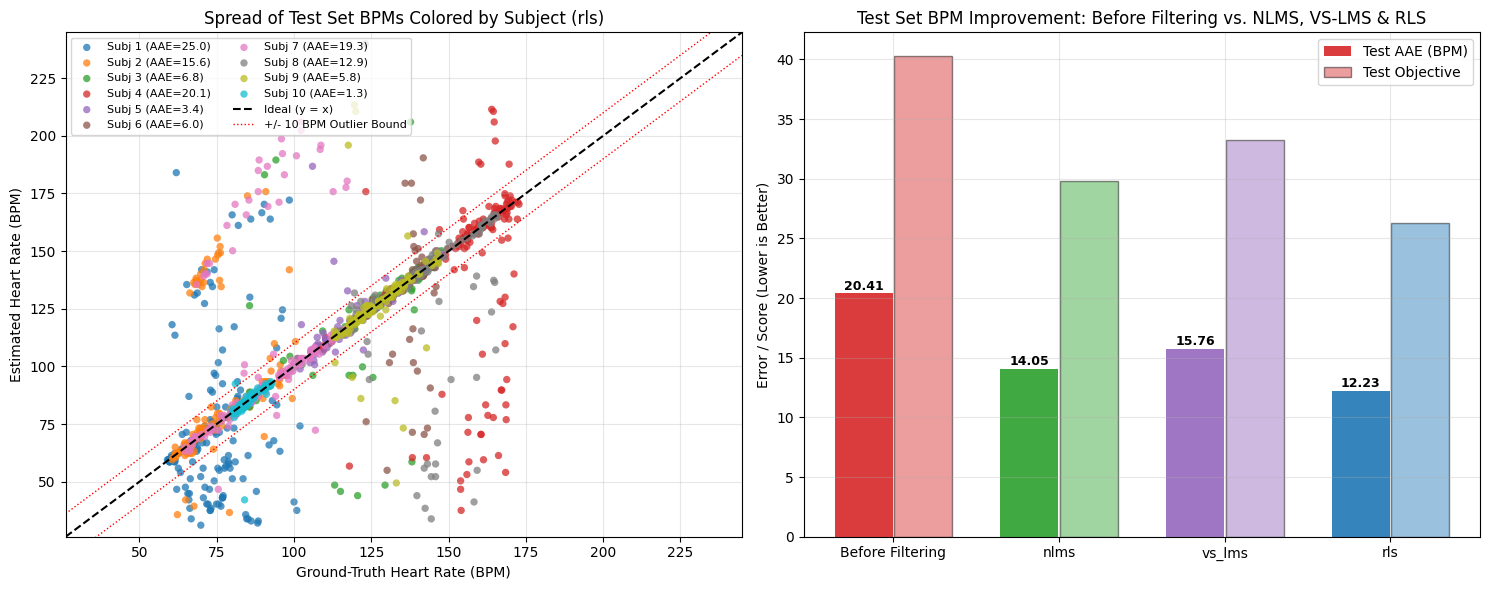

In [3]:
# 1. Compute Before-Filtering Baseline on the Test Set
ppg1_test, ppg2_test, acc_test = preprocess_signal(X_test)
y_pred_before_lms = np.array([
    zero_padded_periodogram_bpm(snr_weighted_late_fusion(ppg1_test[i], ppg2_test[i]), nfft=8192)
    for i in range(len(X_test))
])

def compute_metrics(y_hat, y_true):
    abs_e = np.abs(y_hat - y_true)
    return {
        "obj": objective_function(y_hat, y_true),
        "aae": float(np.mean(abs_e)),
        "rmse": float(np.sqrt(np.mean(abs_e ** 2))),
        "medae": float(np.median(abs_e)),
        "outlier_pct": float(np.mean(abs_e > 10.0) * 100.0),
        "abs_errors": abs_e,
    }

test_eval = {"Before Filtering": {"preds": y_pred_before_lms, **compute_metrics(y_pred_before_lms, y_test)}}
cleaned_signals_by_lms = {}

for algo_name, info in results_by_lms.items():
    preds, sigs = info["model"].predict_with_signals(X_test)
    cleaned_signals_by_lms[algo_name] = sigs
    test_eval[algo_name] = {"preds": preds, **compute_metrics(preds, y_test)}

# Focus detailed plots and subject breakdown on the RLS algorithm
y_test_pred = test_eval["rls"]["preds"]
cleaned_test_signals = cleaned_signals_by_lms["rls"]
abs_errors = test_eval["rls"]["abs_errors"]
outlier_mask = abs_errors > 10.0

print("=" * 94)
print("TEST SET PERFORMANCE COMPARISON (IEEEPPG_TEST.ts — BEFORE FILTERING vs. NLMS, VS-LMS & RLS)")
print("=" * 94)
print(f"{'Method':<18} | {'Objective':>10} | {'AAE (BPM)':>10} | {'RMSE (BPM)':>10} | {'MedAE (BPM)':>11} | {'Outliers (>10 BPM)':>18}")
print("-" * 94)
for name, m in test_eval.items():
    marker = " <-- RLS (Project 2)" if name == "rls" else ""
    print(
        f"{name:<18} | {m['obj']:10.2f} | {m['aae']:10.2f} | "
        f"{m['rmse']:10.2f} | {m['medae']:11.2f} | {m['outlier_pct']:17.2f}%{marker}"
    )
print("=" * 94)

# Per-subject breakdown for the RLS model
unique_test_subjects = np.unique(test_groups)
subj_aae, subj_obj, subj_out = [], [], []
print("\nTEST SET PERFORMANCE BY SUBJECT (RLS PIPELINE):")
print(f"{'Subject':<12} | {'Windows':>8} | {'AAE (BPM)':>10} | {'Objective':>10} | {'Outliers (>10 BPM)':>18}")
print("-" * 68)
for s in unique_test_subjects:
    idx = test_groups == s
    m_s = compute_metrics(y_test_pred[idx], y_test[idx])
    subj_aae.append(m_s["aae"])
    subj_obj.append(m_s["obj"])
    subj_out.append(m_s["outlier_pct"])
    print(f"Subject {s + 1:2d}   | {int(np.sum(idx)):8d} | {m_s['aae']:10.2f} | {m_s['obj']:10.2f} | {m_s['outlier_pct']:17.1f}%")

# Plot 1: Spread of Test BPMs Colored by Subject (RLS) + Method Comparison Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cmap = plt.get_cmap("tab10", len(unique_test_subjects))
for idx_s, s in enumerate(unique_test_subjects):
    mask = test_groups == s
    axes[0].scatter(
        y_test[mask],
        y_test_pred[mask],
        color=cmap(idx_s),
        alpha=0.75,
        s=28,
        edgecolors="none",
        label=f"Subj {s + 1} (AAE={subj_aae[idx_s]:.1f})",
    )

lims = [min(y_test.min(), y_test_pred.min()) - 5, max(y_test.max(), y_test_pred.max()) + 5]
axes[0].plot(lims, lims, "k--", lw=1.5, label="Ideal (y = x)")
axes[0].plot(lims, [l + 10 for l in lims], "r:", lw=1.0, label="+/- 10 BPM Outlier Bound")
axes[0].plot(lims, [l - 10 for l in lims], "r:", lw=1.0)
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_xlabel("Ground-Truth Heart Rate (BPM)")
axes[0].set_ylabel("Estimated Heart Rate (BPM)")
axes[0].set_title("Spread of Test Set BPMs Colored by Subject (rls)")
axes[0].legend(loc="upper left", fontsize=8, ncol=2)

# Right subplot: Before Filtering vs NLMS, VS-LMS & RLS on Test Set
methods = list(test_eval.keys())
aaes = [test_eval[k]["aae"] for k in methods]
objs = [test_eval[k]["obj"] for k in methods]
x_pos = np.arange(len(methods))
bar_colors = ["#d62728", "#2ca02c", "#9467bd", "#1f77b4"]

bars1 = axes[1].bar(x_pos - 0.18, aaes, width=0.35, color=bar_colors, alpha=0.9, label="Test AAE (BPM)")
bars2 = axes[1].bar(x_pos + 0.18, objs, width=0.35, color=bar_colors, alpha=0.45, edgecolor="black", label="Test Objective")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(methods)
axes[1].set_ylabel("Error / Score (Lower is Better)")
axes[1].set_title("Test Set BPM Improvement: Before Filtering vs. NLMS, VS-LMS & RLS")
axes[1].legend()
for b in bars1:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f"{b.get_height():.2f}", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

---
## 4. Visual Progression of a Single Window Over Each Step of the RLS Pipeline

We select a representative motion-corrupted window from the test set and visualize how the signal transforms across each stage of the **RLS** pipeline:
1. **Raw 5D Sensor Input**: Dual PPG channels (`ppg1`, `ppg2`) and 3-axis accelerometer (`accx`, `accy`, `accz`).
2. **Minimal Preprocessing**: Bandpass filtered (`0.5–4.0 Hz`) and normalized to zero mean and unit variance.
3. **Parallel MISO RLS Filtering & Late Fusion**: Primary input $d_1[n]$, RLS-estimated motion artifact $\hat{m}_1[n] = \mathbf{w}_1^T[n]\mathbf{a}[n]$, cleared cardiac error output $e_1[n] = d_1[n] - \hat{m}_1[n]$, and SNR-weighted late fusion $e_{\text{fused}}[n]$.
4. **Before vs. After RLS Recombined Signal & Spectrum**: Pre-filter fused signal $d_{\text{fused}}[n]$ vs. post-RLS fused signal $e_{\text{fused}}[n]$ and their zero-padded periodograms relative to the Ground-Truth BPM.

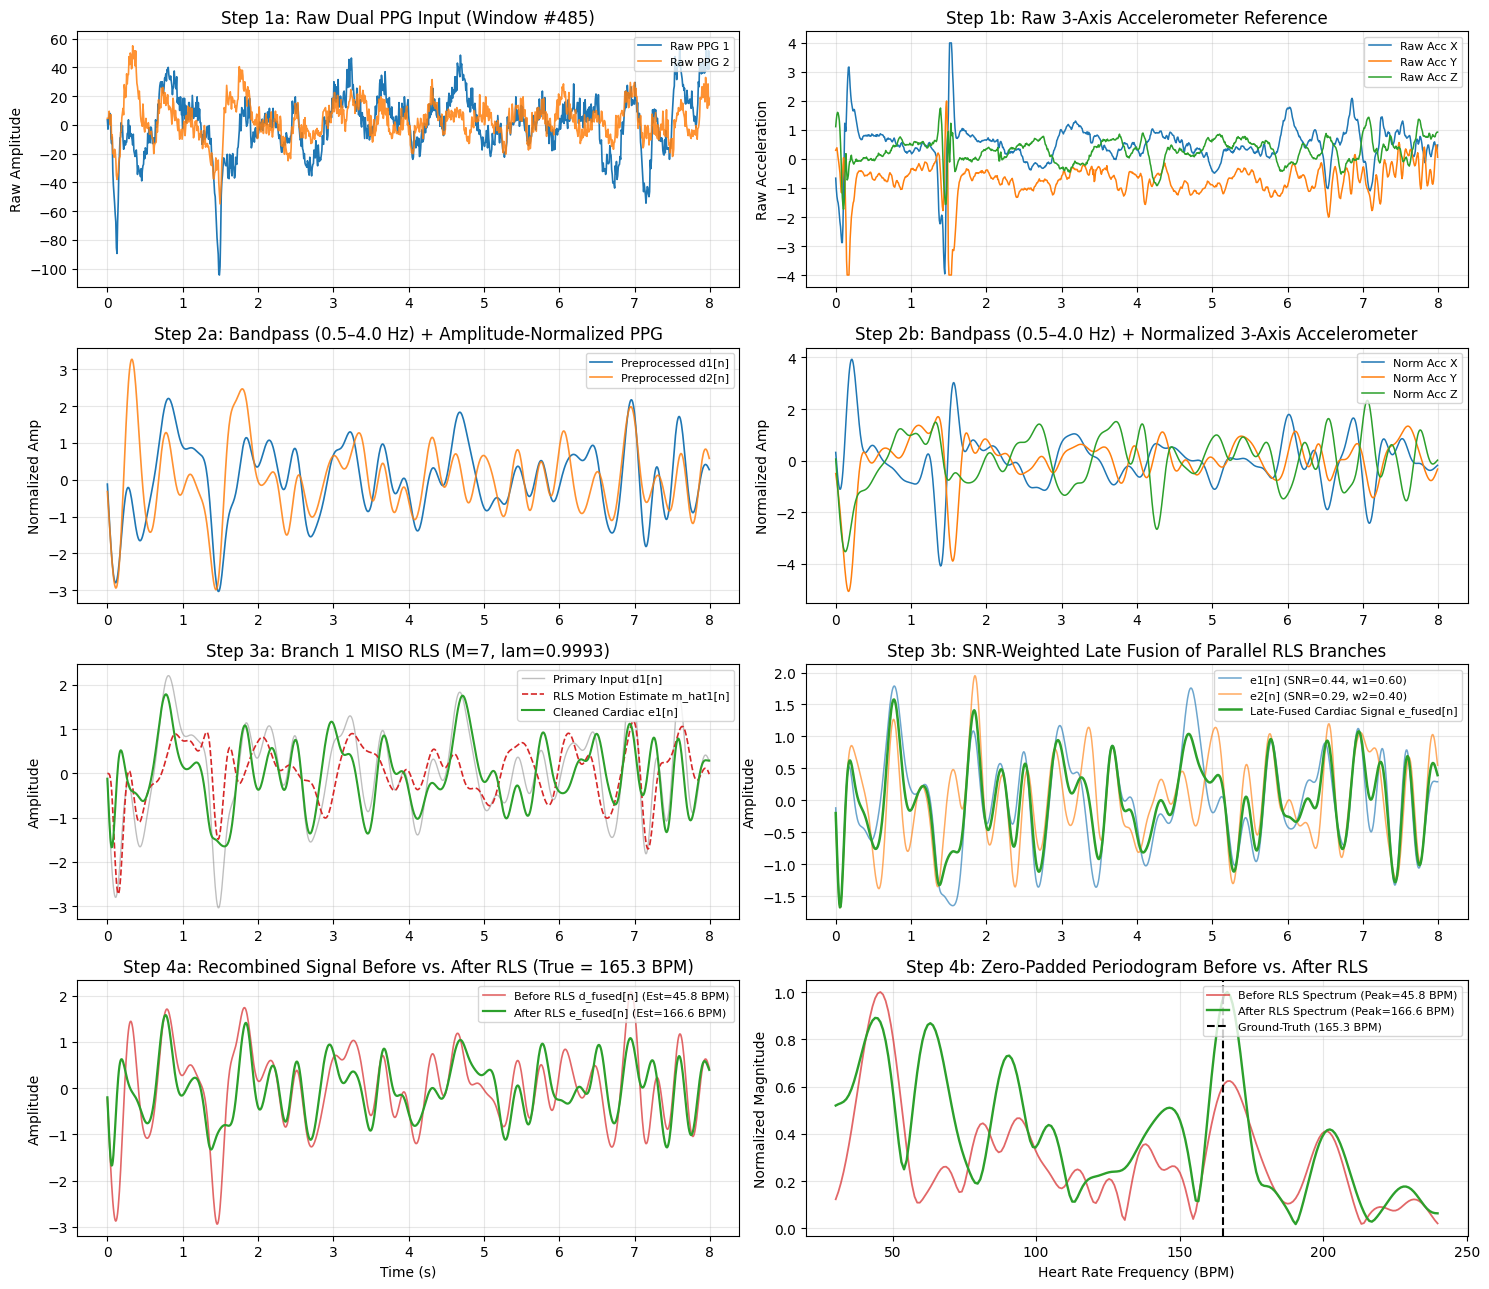

In [4]:
# Pick a window where RLS substantially improves BPM estimation over the unfiltered baseline
before_err = np.abs(y_pred_before_lms - y_test)
after_err = np.abs(y_test_pred - y_test)
improvement = before_err - after_err
demo_idx = int(np.argmax(improvement))
if improvement[demo_idx] <= 0:
    demo_idx = int(np.argmin(after_err))

demo_win = X_test[demo_idx]
demo_true_bpm = float(y_test[demo_idx])
e_Demo, demo_details = rls_model.reconstruct_window(demo_win, return_details=True)
d_Demo = demo_details["d_fused"]
demo_before_bpm = float(y_pred_before_lms[demo_idx])
demo_after_bpm = float(y_test_pred[demo_idx])

t_axis = np.arange(WIN) / FS

fig, axes = plt.subplots(4, 2, figsize=(15, 13))

# Row 1: Raw PPG & Raw Accelerometer
axes[0, 0].plot(t_axis, demo_win[0], label="Raw PPG 1", color="#1f77b4", lw=1.2)
axes[0, 0].plot(t_axis, demo_win[1], label="Raw PPG 2", color="#ff7f0e", lw=1.2, alpha=0.85)
axes[0, 0].set_title(f"Step 1a: Raw Dual PPG Input (Window #{demo_idx})")
axes[0, 0].set_ylabel("Raw Amplitude")
axes[0, 0].legend(loc="upper right", fontsize=8)

axes[0, 1].plot(t_axis, demo_win[2], label="Raw Acc X", lw=1.1)
axes[0, 1].plot(t_axis, demo_win[3], label="Raw Acc Y", lw=1.1)
axes[0, 1].plot(t_axis, demo_win[4], label="Raw Acc Z", lw=1.1)
axes[0, 1].set_title("Step 1b: Raw 3-Axis Accelerometer Reference")
axes[0, 1].set_ylabel("Raw Acceleration")
axes[0, 1].legend(loc="upper right", fontsize=8)

# Row 2: Preprocessed (Bandpass 0.5-4.0 Hz + Normalized)
axes[1, 0].plot(t_axis, demo_details["ppg1"], label="Preprocessed d1[n]", color="#1f77b4", lw=1.2)
axes[1, 0].plot(t_axis, demo_details["ppg2"], label="Preprocessed d2[n]", color="#ff7f0e", lw=1.2, alpha=0.85)
axes[1, 0].set_title("Step 2a: Bandpass (0.5–4.0 Hz) + Amplitude-Normalized PPG")
axes[1, 0].set_ylabel("Normalized Amp")
axes[1, 0].legend(loc="upper right", fontsize=8)

axes[1, 1].plot(t_axis, demo_details["acc"][0], label="Norm Acc X", lw=1.1)
axes[1, 1].plot(t_axis, demo_details["acc"][1], label="Norm Acc Y", lw=1.1)
axes[1, 1].plot(t_axis, demo_details["acc"][2], label="Norm Acc Z", lw=1.1)
axes[1, 1].set_title("Step 2b: Bandpass (0.5–4.0 Hz) + Normalized 3-Axis Accelerometer")
axes[1, 1].set_ylabel("Normalized Amp")
axes[1, 1].legend(loc="upper right", fontsize=8)

# Row 3: Adaptive MISO RLS Filtering on Branch 1 & Branch 2
axes[2, 0].plot(t_axis, demo_details["ppg1"], label="Primary Input d1[n]", color="gray", alpha=0.5, lw=1.0)
axes[2, 0].plot(t_axis, demo_details["m_hat1"], label="RLS Motion Estimate m_hat1[n]", color="#d62728", lw=1.2, ls="--")
axes[2, 0].plot(t_axis, demo_details["e1"], label="Cleaned Cardiac e1[n]", color="#2ca02c", lw=1.5)
axes[2, 0].set_title(f"Step 3a: Branch 1 MISO RLS (M={rls_model.M}, lam={rls_model.lms_params['lam']:.4f})")
axes[2, 0].set_ylabel("Amplitude")
axes[2, 0].legend(loc="upper right", fontsize=8)

f_info = demo_details["fusion_info"]
axes[2, 1].plot(t_axis, demo_details["e1"], label=f"e1[n] (SNR={f_info['snr1']:.2f}, w1={f_info['w1']:.2f})", color="#1f77b4", alpha=0.65, lw=1.1)
axes[2, 1].plot(t_axis, demo_details["e2"], label=f"e2[n] (SNR={f_info['snr2']:.2f}, w2={f_info['w2']:.2f})", color="#ff7f0e", alpha=0.65, lw=1.1)
axes[2, 1].plot(t_axis, e_Demo, label="Late-Fused Cardiac Signal e_fused[n]", color="#2ca02c", lw=1.8)
axes[2, 1].set_title("Step 3b: SNR-Weighted Late Fusion of Parallel RLS Branches")
axes[2, 1].set_ylabel("Amplitude")
axes[2, 1].legend(loc="upper right", fontsize=8)

# Row 4: Recombined Signal Before vs. After RLS (Time Domain & Periodogram Spectrum)
axes[3, 0].plot(t_axis, d_Demo, label=f"Before RLS d_fused[n] (Est={demo_before_bpm:.1f} BPM)", color="#d62728", alpha=0.7, lw=1.2)
axes[3, 0].plot(t_axis, e_Demo, label=f"After RLS e_fused[n] (Est={demo_after_bpm:.1f} BPM)", color="#2ca02c", lw=1.6)
axes[3, 0].set_title(f"Step 4a: Recombined Signal Before vs. After RLS (True = {demo_true_bpm:.1f} BPM)")
axes[3, 0].set_xlabel("Time (s)")
axes[3, 0].set_ylabel("Amplitude")
axes[3, 0].legend(loc="upper right", fontsize=8)

nfft_plot = 8192
freqs_bpm = 60.0 * np.fft.rfftfreq(nfft_plot, d=1.0 / FS)
band_m = (freqs_bpm >= 30.0) & (freqs_bpm <= 240.0)
spec_before = np.abs(np.fft.rfft((d_Demo - d_Demo.mean()) * np.hanning(WIN), n=nfft_plot))[band_m]
spec_after = np.abs(np.fft.rfft((e_Demo - e_Demo.mean()) * np.hanning(WIN), n=nfft_plot))[band_m]
spec_before /= (spec_before.max() + 1e-12)
spec_after /= (spec_after.max() + 1e-12)

axes[3, 1].plot(freqs_bpm[band_m], spec_before, label=f"Before RLS Spectrum (Peak={demo_before_bpm:.1f} BPM)", color="#d62728", alpha=0.7, lw=1.3)
axes[3, 1].plot(freqs_bpm[band_m], spec_after, label=f"After RLS Spectrum (Peak={demo_after_bpm:.1f} BPM)", color="#2ca02c", lw=1.7)
axes[3, 1].axvline(demo_true_bpm, color="black", ls="--", lw=1.5, label=f"Ground-Truth ({demo_true_bpm:.1f} BPM)")
axes[3, 1].set_title("Step 4b: Zero-Padded Periodogram Before vs. After RLS")
axes[3, 1].set_xlabel("Heart Rate Frequency (BPM)")
axes[3, 1].set_ylabel("Normalized Magnitude")
axes[3, 1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

---
## 5. Outlier vs. Good Functioning Example of the RLS Algorithm

Next, we compute the fraction of test windows that are outliers ($|\hat{y}_{\text{RLS}} - y_{\text{true}}| > 10\text{ BPM}$) for the **RLS** pipeline and compare:
- **Left Column (Good RLS Example)**: Triaxial accelerometer reference on top, raw preprocessed PPG signal in the middle, and the RLS-cleaned cardiac waveform directly below it.
- **Right Column (Outlier RLS Example)**: Triaxial accelerometer reference on top, raw preprocessed PPG signal of a severe motion-corrupted RLS outlier in the middle, and its RLS-cleaned waveform directly below it.

RLS Test Set Outlier Fraction (|Error| > 10 BPM): 286 / 1328 windows (21.54%)
RLS Well-Detected Fraction    (|Error| <= 10 BPM): 1042 / 1328 windows (78.46%)


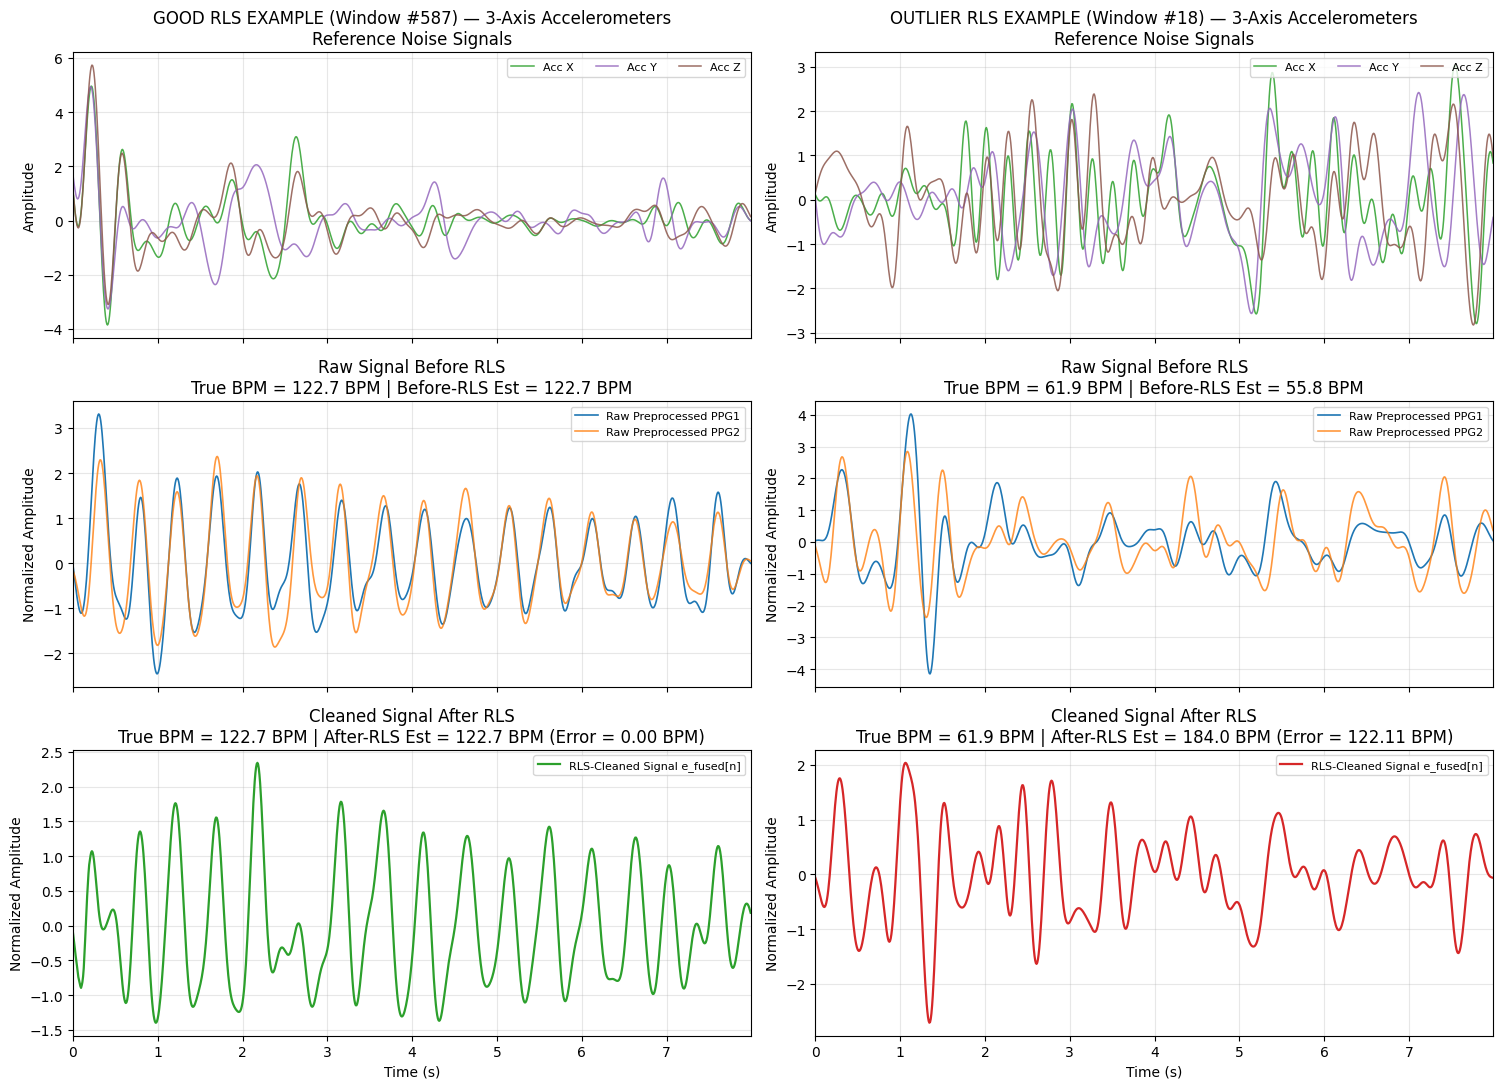

In [5]:
n_outliers = int(np.sum(outlier_mask))
outlier_fraction = float(np.mean(outlier_mask))
print(
    f"RLS Test Set Outlier Fraction (|Error| > 10 BPM): {n_outliers} /"
    f" {len(y_test)} windows ({outlier_fraction * 100:.2f}%)"
)
print(
    "RLS Well-Detected Fraction    (|Error| <= 10 BPM):"
    f" {len(y_test) - n_outliers} / {len(y_test)} windows ({(1.0 - outlier_fraction) * 100:.2f}%)"
)

good_idx = int(np.argmin(abs_errors))
outlier_idx = int(np.argmax(abs_errors))

e_good, good_det = rls_model.reconstruct_window(
    X_test[good_idx], return_details=True
)
e_out, out_det = rls_model.reconstruct_window(
    X_test[outlier_idx], return_details=True
)

def get_acc_channels(det, raw_window):
    ax = det["accx"] if "accx" in det else det["acc"][0]
    ay = det["accy"] if "accy" in det else det["acc"][1]
    az = det["accz"] if "accz" in det else det["acc"][2]
    return ax, ay, az

good_ax, good_ay, good_az = get_acc_channels(good_det, X_test[good_idx])
out_ax, out_ay, out_az = get_acc_channels(out_det, X_test[outlier_idx])

# 3 Rows x 2 Columns layout with shared x-axis
fig, axes = plt.subplots(3, 2, figsize=(15, 11), sharex=True)
axes[0, 0].set_xlim(t_axis[0], t_axis[-1])

# ============================================================================
# LEFT COLUMN: Good RLS Detection Example
# ============================================================================
axes[0, 0].plot(t_axis, good_ax, label="Acc X", color="#2ca02c", lw=1.1, alpha=0.85)
axes[0, 0].plot(t_axis, good_ay, label="Acc Y", color="#9467bd", lw=1.1, alpha=0.85)
axes[0, 0].plot(t_axis, good_az, label="Acc Z", color="#8c564b", lw=1.1, alpha=0.85)
axes[0, 0].set_title(
    f"GOOD RLS EXAMPLE (Window #{good_idx}) — 3-Axis Accelerometers\nReference Noise Signals"
)
axes[0, 0].set_ylabel("Amplitude")
axes[0, 0].legend(loc="upper right", fontsize=8, ncol=3)
axes[0, 0].grid(alpha=0.3)

axes[1, 0].plot(t_axis, good_det["ppg1"], label="Raw Preprocessed PPG1", color="#1f77b4", lw=1.2)
axes[1, 0].plot(t_axis, good_det["ppg2"], label="Raw Preprocessed PPG2", color="#ff7f0e", lw=1.2, alpha=0.8)
axes[1, 0].set_title(
    "Raw Signal Before RLS\n"
    f"True BPM = {y_test[good_idx]:.1f} BPM | Before-RLS Est = {y_pred_before_lms[good_idx]:.1f} BPM"
)
axes[1, 0].set_ylabel("Normalized Amplitude")
axes[1, 0].legend(loc="upper right", fontsize=8)
axes[1, 0].grid(alpha=0.3)

axes[2, 0].plot(t_axis, e_good, label="RLS-Cleaned Signal e_fused[n]", color="#2ca02c", lw=1.6)
axes[2, 0].set_title(
    "Cleaned Signal After RLS\n"
    f"True BPM = {y_test[good_idx]:.1f} BPM | After-RLS Est = "
    f"{y_test_pred[good_idx]:.1f} BPM (Error = {abs_errors[good_idx]:.2f} BPM)"
)
axes[2, 0].set_xlabel("Time (s)")
axes[2, 0].set_ylabel("Normalized Amplitude")
axes[2, 0].legend(loc="upper right", fontsize=8)
axes[2, 0].grid(alpha=0.3)

# ============================================================================
# RIGHT COLUMN: Outlier RLS Detection Example
# ============================================================================
axes[0, 1].plot(t_axis, out_ax, label="Acc X", color="#2ca02c", lw=1.1, alpha=0.85)
axes[0, 1].plot(t_axis, out_ay, label="Acc Y", color="#9467bd", lw=1.1, alpha=0.85)
axes[0, 1].plot(t_axis, out_az, label="Acc Z", color="#8c564b", lw=1.1, alpha=0.85)
axes[0, 1].set_title(
    f"OUTLIER RLS EXAMPLE (Window #{outlier_idx}) — 3-Axis Accelerometers\nReference Noise Signals"
)
axes[0, 1].set_ylabel("Amplitude")
axes[0, 1].legend(loc="upper right", fontsize=8, ncol=3)
axes[0, 1].grid(alpha=0.3)

axes[1, 1].plot(t_axis, out_det["ppg1"], label="Raw Preprocessed PPG1", color="#1f77b4", lw=1.2)
axes[1, 1].plot(t_axis, out_det["ppg2"], label="Raw Preprocessed PPG2", color="#ff7f0e", lw=1.2, alpha=0.8)
axes[1, 1].set_title(
    "Raw Signal Before RLS\n"
    f"True BPM = {y_test[outlier_idx]:.1f} BPM | Before-RLS Est = {y_pred_before_lms[outlier_idx]:.1f} BPM"
)
axes[1, 1].set_ylabel("Normalized Amplitude")
axes[1, 1].legend(loc="upper right", fontsize=8)
axes[1, 1].grid(alpha=0.3)

axes[2, 1].plot(t_axis, e_out, label="RLS-Cleaned Signal e_fused[n]", color="#d62728", lw=1.6)
axes[2, 1].set_title(
    "Cleaned Signal After RLS\n"
    f"True BPM = {y_test[outlier_idx]:.1f} BPM | After-RLS Est = "
    f"{y_test_pred[outlier_idx]:.1f} BPM (Error = {abs_errors[outlier_idx]:.2f} BPM)"
)
axes[2, 1].set_xlabel("Time (s)")
axes[2, 1].set_ylabel("Normalized Amplitude")
axes[2, 1].legend(loc="upper right", fontsize=8)
axes[2, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
## 6. Running RLS on the Same Outlier Window Used in Project 1 (Window #481)

In Project 1, the worst-case outlier analyzed in the final figure was **Test Window #481** (where the Project 1 winning `vs_lms` model estimated `36.6 BPM` against a Ground-Truth of `168.6 BPM`, yielding an error of `132.01 BPM` due to abrupt, impulsive accelerometer impacts around $t = 1\text{ s}$ and $t = 6.5\text{ s}$).

Below, we run the optimized **RLS (`rls`)** algorithm on **that exact same outlier window from Project 1 (`Window #481`)** and compare the Project 1 LMS reconstruction (Left Column) directly against the Project 2 RLS reconstruction (Right Column).

COMPARISON ON PROJECT 1 OUTLIER (Test Window #481 | True BPM = 168.6 BPM)
   Before Filtering : Est =  140.1 BPM | |Error| =  28.55 BPM
   NLMS (Project 1) : Est =   36.6 BPM | |Error| = 132.01 BPM
   VS-LMS (Proj. 1) : Est =   36.6 BPM | |Error| = 132.01 BPM
   RLS (Project 2)  : Est =   76.9 BPM | |Error| =  91.73 BPM


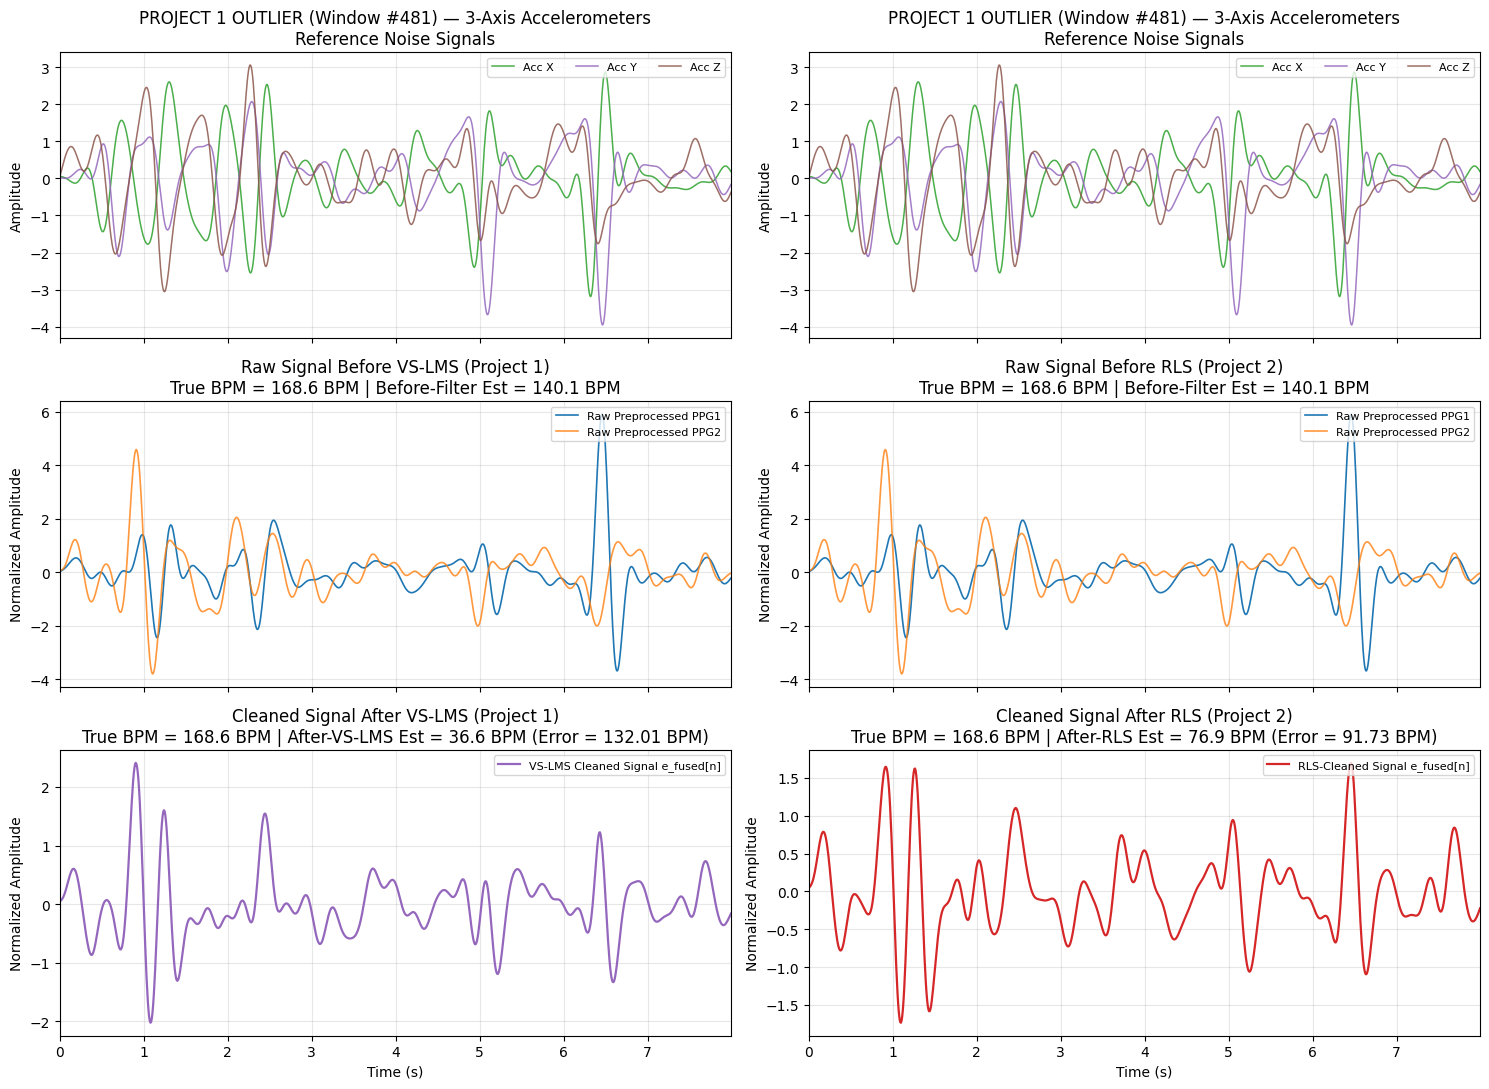

In [6]:
# Same outlier window index analyzed in Project 1 (Window #481, worst error of vs_lms)
project1_outlier_idx = 481

vs_lms_model = results_by_lms["vs_lms"]["model"]
e_p1_vslms, det_p1_vslms = vs_lms_model.reconstruct_window(
    X_test[project1_outlier_idx], return_details=True
)
e_p1_rls, det_p1_rls = rls_model.reconstruct_window(
    X_test[project1_outlier_idx], return_details=True
)

true_bpm_481 = float(y_test[project1_outlier_idx])
before_bpm_481 = float(y_pred_before_lms[project1_outlier_idx])
nlms_bpm_481 = float(test_eval["nlms"]["preds"][project1_outlier_idx])
nlms_err_481 = float(test_eval["nlms"]["abs_errors"][project1_outlier_idx])
vslms_bpm_481 = float(test_eval["vs_lms"]["preds"][project1_outlier_idx])
vslms_err_481 = float(test_eval["vs_lms"]["abs_errors"][project1_outlier_idx])
rls_bpm_481 = float(test_eval["rls"]["preds"][project1_outlier_idx])
rls_err_481 = float(test_eval["rls"]["abs_errors"][project1_outlier_idx])

print("=" * 88)
print(f"COMPARISON ON PROJECT 1 OUTLIER (Test Window #{project1_outlier_idx} | True BPM = {true_bpm_481:.1f} BPM)")
print("=" * 88)
print(f"   Before Filtering : Est = {before_bpm_481:6.1f} BPM | |Error| = {abs(before_bpm_481 - true_bpm_481):6.2f} BPM")
print(f"   NLMS (Project 1) : Est = {nlms_bpm_481:6.1f} BPM | |Error| = {nlms_err_481:6.2f} BPM")
print(f"   VS-LMS (Proj. 1) : Est = {vslms_bpm_481:6.1f} BPM | |Error| = {vslms_err_481:6.2f} BPM")
print(f"   RLS (Project 2)  : Est = {rls_bpm_481:6.1f} BPM | |Error| = {rls_err_481:6.2f} BPM")
print("=" * 88)

p1_ax, p1_ay, p1_az = get_acc_channels(det_p1_rls, X_test[project1_outlier_idx])

fig, axes = plt.subplots(3, 2, figsize=(15, 11), sharex=True)
axes[0, 0].set_xlim(t_axis[0], t_axis[-1])

# ============================================================================
# LEFT COLUMN: Project 1 Winner (VS-LMS) on Project 1 Outlier (Window #481)
# ============================================================================
axes[0, 0].plot(t_axis, p1_ax, label="Acc X", color="#2ca02c", lw=1.1, alpha=0.85)
axes[0, 0].plot(t_axis, p1_ay, label="Acc Y", color="#9467bd", lw=1.1, alpha=0.85)
axes[0, 0].plot(t_axis, p1_az, label="Acc Z", color="#8c564b", lw=1.1, alpha=0.85)
axes[0, 0].set_title(
    f"PROJECT 1 OUTLIER (Window #{project1_outlier_idx}) — 3-Axis Accelerometers\nReference Noise Signals"
)
axes[0, 0].set_ylabel("Amplitude")
axes[0, 0].legend(loc="upper right", fontsize=8, ncol=3)
axes[0, 0].grid(alpha=0.3)

axes[1, 0].plot(t_axis, det_p1_vslms["ppg1"], label="Raw Preprocessed PPG1", color="#1f77b4", lw=1.2)
axes[1, 0].plot(t_axis, det_p1_vslms["ppg2"], label="Raw Preprocessed PPG2", color="#ff7f0e", lw=1.2, alpha=0.8)
axes[1, 0].set_title(
    "Raw Signal Before VS-LMS (Project 1)\n"
    f"True BPM = {true_bpm_481:.1f} BPM | Before-Filter Est = {before_bpm_481:.1f} BPM"
)
axes[1, 0].set_ylabel("Normalized Amplitude")
axes[1, 0].legend(loc="upper right", fontsize=8)
axes[1, 0].grid(alpha=0.3)

axes[2, 0].plot(t_axis, e_p1_vslms, label="VS-LMS Cleaned Signal e_fused[n]", color="#9467bd", lw=1.6)
axes[2, 0].set_title(
    "Cleaned Signal After VS-LMS (Project 1)\n"
    f"True BPM = {true_bpm_481:.1f} BPM | After-VS-LMS Est = "
    f"{vslms_bpm_481:.1f} BPM (Error = {vslms_err_481:.2f} BPM)"
)
axes[2, 0].set_xlabel("Time (s)")
axes[2, 0].set_ylabel("Normalized Amplitude")
axes[2, 0].legend(loc="upper right", fontsize=8)
axes[2, 0].grid(alpha=0.3)

# ============================================================================
# RIGHT COLUMN: Project 2 RLS on the Exact Same Project 1 Outlier (Window #481)
# ============================================================================
axes[0, 1].plot(t_axis, p1_ax, label="Acc X", color="#2ca02c", lw=1.1, alpha=0.85)
axes[0, 1].plot(t_axis, p1_ay, label="Acc Y", color="#9467bd", lw=1.1, alpha=0.85)
axes[0, 1].plot(t_axis, p1_az, label="Acc Z", color="#8c564b", lw=1.1, alpha=0.85)
axes[0, 1].set_title(
    f"PROJECT 1 OUTLIER (Window #{project1_outlier_idx}) — 3-Axis Accelerometers\nReference Noise Signals"
)
axes[0, 1].set_ylabel("Amplitude")
axes[0, 1].legend(loc="upper right", fontsize=8, ncol=3)
axes[0, 1].grid(alpha=0.3)

axes[1, 1].plot(t_axis, det_p1_rls["ppg1"], label="Raw Preprocessed PPG1", color="#1f77b4", lw=1.2)
axes[1, 1].plot(t_axis, det_p1_rls["ppg2"], label="Raw Preprocessed PPG2", color="#ff7f0e", lw=1.2, alpha=0.8)
axes[1, 1].set_title(
    "Raw Signal Before RLS (Project 2)\n"
    f"True BPM = {true_bpm_481:.1f} BPM | Before-Filter Est = {before_bpm_481:.1f} BPM"
)
axes[1, 1].set_ylabel("Normalized Amplitude")
axes[1, 1].legend(loc="upper right", fontsize=8)
axes[1, 1].grid(alpha=0.3)

axes[2, 1].plot(t_axis, e_p1_rls, label="RLS-Cleaned Signal e_fused[n]", color="#d62728", lw=1.6)
axes[2, 1].set_title(
    "Cleaned Signal After RLS (Project 2)\n"
    f"True BPM = {true_bpm_481:.1f} BPM | After-RLS Est = "
    f"{rls_bpm_481:.1f} BPM (Error = {rls_err_481:.2f} BPM)"
)
axes[2, 1].set_xlabel("Time (s)")
axes[2, 1].set_ylabel("Normalized Amplitude")
axes[2, 1].legend(loc="upper right", fontsize=8)
axes[2, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()